In [1]:
import pandas as pd

In [2]:
calls = pd.read_csv("data/weekday_daytime_calls.csv")
calls.head()

,incident_id,incident_datetime,initial_call_type,initial_severity_level_code,final_call_type,final_severity_level_code,first_assignment_datetime,valid_dispatch_rspns_time_indc,dispatch_response_seconds_qy,first_activation_datetime,...,zipcode,policeprecinct,citycouncildistrict,communitydistrict,communityschooldistrict,congressionaldistrict,reopen_indicator,special_event_indicator,standby_indicator,transfer_indicator
0,80936483,2025-01-01T09:00:31.000,CARDBR,2,CARDBR,2,2025-01-01T09:00:41.000,Y,10,2025-01-01T09:00:45.000,...,11207.0,75.0,37.0,305.0,19.0,7.0,N,N,N,N
1,80936490,2025-01-01T09:01:45.000,ABDPN,5,ABDPN,5,2025-01-01T09:02:02.000,Y,17,2025-01-01T09:02:57.000,...,11208.0,75.0,37.0,305.0,19.0,7.0,N,N,N,N
2,80936492,2025-01-01T09:02:13.000,UNKNOW,4,CARD,3,2025-01-01T09:02:29.000,Y,16,2025-01-01T09:02:32.000,...,11207.0,75.0,37.0,305.0,19.0,7.0,N,N,N,N
3,80936502,2025-01-01T09:06:30.000,INJURY,5,INJURY,5,2025-01-01T09:06:41.000,Y,11,2025-01-01T09:06:56.000,...,11212.0,73.0,42.0,316.0,23.0,8.0,N,N,N,N
4,80936508,2025-01-01T09:07:45.000,INJURY,5,INJURY,5,2025-01-01T09:08:01.000,Y,16,2025-01-01T09:08:16.000,...,11232.0,66.0,38.0,312.0,15.0,7.0,N,N,N,N


In [3]:
import pandas as pd

calls = pd.read_csv("data/weekday_daytime_calls.csv", dtype={"zipcode": "string"})
calls["incident_datetime"] = pd.to_datetime(
    calls["incident_datetime"], errors="coerce"
)

# Handle ZIPs exported as strings like "11207.0".
calls["zipcode"] = (
    calls["zipcode"]
    .str.strip()
    .str.replace(r"\.0+$", "", regex=True)
)
valid_zip = calls["zipcode"].str.fullmatch(r"\d{5}", na=False)

id_col = next(
    (col for col in ["incident_id", "ncident_id"] if col in calls.columns),
    None,
)

print("Rows:", len(calls))
print("Date range:", calls["incident_datetime"].min(), "to",
      calls["incident_datetime"].max())
print("Missing or invalid timestamps:", calls["incident_datetime"].isna().sum())
print("Missing or invalid ZIPs:", (~valid_zip).sum())
if id_col:
    print("Repeated incident IDs:", calls[id_col].dropna().duplicated().sum())

display(pd.crosstab(
    calls["incident_datetime"].dt.day_name(),
    calls["incident_datetime"].dt.hour,
))
display(calls.groupby(calls["incident_datetime"].dt.to_period("M")).size())

Rows: 203682
Date range: 2025-01-01 09:00:31 to 2025-12-31 20:59:16
Missing or invalid timestamps: 0
Missing or invalid ZIPs: 1185
Repeated incident IDs: 0


incident_datetime,9,10,11,12,13,14,15,16,17,18,19,20
incident_datetime,,,,,,,,,,,,
Friday,3061,3423,3374,3519,3478,3461,3498,3527,3354,3356,3351,3281
Monday,3181,3409,3500,3610,3470,3569,3547,3496,3529,3439,3349,3112
Thursday,3066,3265,3374,3555,3605,3420,3478,3435,3328,3220,3168,3133
Tuesday,3094,3316,3520,3453,3559,3556,3515,3576,3523,3357,3129,3080
Wednesday,3119,3391,3375,3600,3565,3712,3565,3488,3421,3392,3219,3216


incident_datetime
2025-01    18182
2025-02    15290
2025-03    16047
2025-04    17156
2025-05    17032
2025-06    17251
2025-07    18083
2025-08    15914
2025-09    17950
2025-10    17241
2025-11    15044
2025-12    18492
Freq: M, dtype: int64

In [4]:
invalid_zips = calls.loc[~valid_zip].copy()

# How many are missing versus malformed?
display(
    invalid_zips["zipcode"]
    .fillna("<missing>")
    .replace("", "<blank>")
    .value_counts()
    .rename("incident_count")
    .to_frame()
)

# See example incidents and their recorded geography.
cols = ["incident_datetime", "zipcode", "communitydistrict", "policeprecinct"]
if id_col is not None:
    cols.insert(0, id_col)

display(invalid_zips[cols].head(20))

,incident_count
zipcode,
<missing>,1185


,incident_id,incident_datetime,zipcode,communitydistrict,policeprecinct
80,80936795,2025-01-01 10:18:27,<NA>,NaN,NaN
206,80937357,2025-01-01 12:32:07,<NA>,NaN,NaN
431,80938423,2025-01-01 16:13:26,<NA>,NaN,NaN
642,80939340,2025-01-01 20:10:45,<NA>,NaN,NaN
964,80942791,2025-01-02 12:54:18,<NA>,NaN,NaN
1308,80944567,2025-01-02 18:34:45,<NA>,NaN,NaN
1541,80947678,2025-01-03 10:15:30,<NA>,NaN,NaN
1676,80948208,2025-01-03 12:05:34,<NA>,NaN,NaN
1742,80948531,2025-01-03 13:05:41,<NA>,NaN,NaN
1829,80948974,2025-01-03 14:22:03,<NA>,NaN,NaN


In [5]:
usable = calls.loc[valid_zip & calls["incident_datetime"].notna()].copy()

In [6]:
test_start = pd.Timestamp("2025-11-01")

usable["split"] = "train"
usable.loc[usable["incident_datetime"] >= test_start, "split"] = "test"

weights = (
    usable.groupby(["zipcode", "split"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=["train", "test"], fill_value=0)
    .rename(columns={"train": "calls_train", "test": "calls_test"})
    .reset_index()
)

display(
    weights.rename_axis(columns=None)
    .sort_values("calls_train", ascending=False)
    .reset_index(drop=True)
    .head(10)
)

,zipcode,calls_train,calls_test
0,11207,10466,2007
1,11212,10201,1975
2,11201,9532,1898
3,11208,8225,1648
4,11226,7283,1508
5,11206,7272,1392
6,11233,7097,1398
7,11203,6008,1197
8,11224,5589,1061
9,11236,5383,1139


In [7]:
assert weights["zipcode"].is_unique
assert weights[["calls_train", "calls_test"]].sum().sum() == len(usable)

In [8]:
weights.to_csv("data/call_weights_by_zip.csv", index=False)

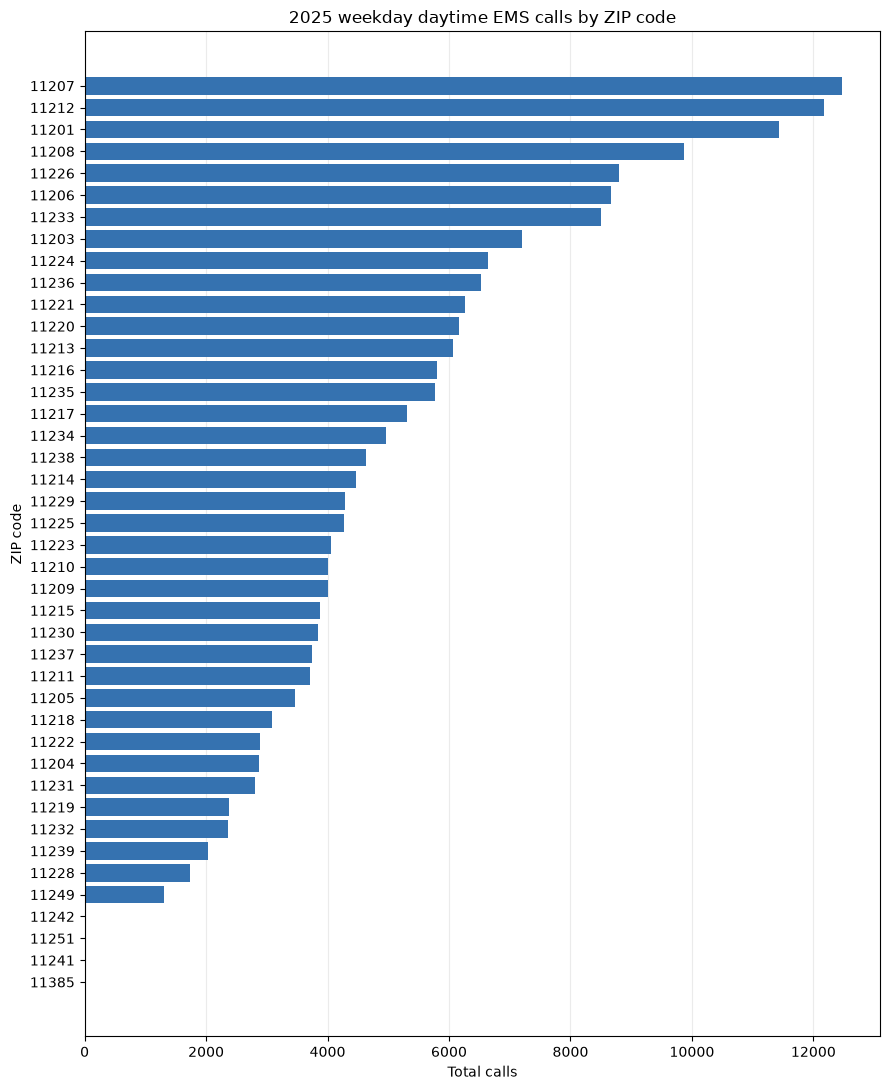

In [9]:
import matplotlib.pyplot as plt

zip_demand = (
    weights.assign(total_calls=weights["calls_train"] + weights["calls_test"])
    .sort_values("total_calls")
)

fig, ax = plt.subplots(figsize=(9, 11))
ax.barh(zip_demand["zipcode"].astype(str), zip_demand["total_calls"], color="#3572B0")
ax.set(
    title="2025 weekday daytime EMS calls by ZIP code",
    xlabel="Total calls",
    ylabel="ZIP code",
)
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()